# Day 6 · Vintage — The Great Storm of 1987

### #30DayMapChallenge 2026 · ERA5 reanalysis (Copernicus / C3S) · Map by Emma Pidduck

Overnight on **15–16 October 1987**, an explosively deepening depression bombed out over the
Bay of Biscay and ran across southern England. By the small hours its central pressure was near
**953 hPa**; gusts topped **100 mph** on the south coast. Around **15 million trees** came down
and **18 people** lost their lives — the worst storm to strike this part of England since the
Great Storm of **1703**.

Here it is drawn the way the Met Office would have at the time — a **surface pressure analysis**
in sepia ink on aged paper: labelled isobars, wind barbs in knots, hand-marked fronts, the
depression's track across the night. The *look* is mid-century; the *data* is modern — one hour
from the **ERA5 reanalysis**, which now reaches back to 1940, so a storm from before many of us
were born can be re-analysed on an open, reproducible dataset.

Self-contained: method, code, output, data licence and tools in one place.

## Method

- Pull **surface** (mean sea-level pressure, 10 m wind) and **850 hPa** (temperature, specific
  humidity) from **ERA5** across the night of the storm, 15 Oct → 16 Oct.
- Work at the chart hour **16 Oct 1987, 00 UTC** — the depression over the western Channel.
- **Isobars** every 4 hPa, with a slight pen-and-ink wobble; **wind barbs** in knots.
- **Fronts** traced along the ridge of the **850 hPa equivalent-potential-temperature (θₑ)
  gradient**, classified warm/cold by the sign of θₑ advection, and drawn with the usual
  triangles (cold) and semicircles (warm) pointing into the warm air.
- Mark the **low** (de-duplicated to the single storm centre) and plot the **depression's track**
  from the hourly MSLP minima.
- Dress it: aged paper, a serif face, a plate header and a descriptive caption — the look of the
  charts of the day.

*Reanalysis smooths the very deepest gradients, so a chart hand-drawn from barographs at the time
would be a touch tighter still — but the shape of the night is all here.*

## Licence & attribution

**ERA5** is produced by **ECMWF** for the **Copernicus Climate Change Service (C3S)** and
distributed through the **Climate Data Store (CDS)**.

> Contains modified Copernicus Climate Change Service information [2026]. Neither the European
> Commission nor ECMWF is responsible for any use of the Copernicus information.

`© ECMWF · Generated using Copernicus Climate Change Service information · via the CDS`

Coastlines are **Natural Earth** (public domain).

## Tools

| Tool | Role |
|---|---|
| [`cdsapi`](https://github.com/ecmwf/cdsapi) | retrieve ERA5 from the Copernicus **Climate Data Store** |
| [`xarray`](https://docs.xarray.dev) | read the NetCDF, select the chart hour |
| `scipy.ndimage` · `scipy.interpolate` | θₑ gradient, front tracing, centre de-dup, spline fronts |
| `cartopy` · `matplotlib` | projection, coastline, the vintage render |

ERA5 is 0.25° hourly — plenty for a synoptic chart. Reaching the CDS needs a free
[CDS account](https://cds.climate.copernicus.eu/) and accepting the ERA5 licence once.

In [1]:
# Run once if needed (uncomment):
#!pip install cdsapi netcdf4 xarray scipy cartopy matplotlib

import os, warnings; warnings.filterwarnings("ignore")
import numpy as np, xarray as xr
from scipy.ndimage import gaussian_filter, median_filter, minimum_filter, maximum_filter

WHEN   = "1987-10-16T00:00"                 # the hour of the chart
AREA   = [66, -25, 44, 20]                  # N, W, S, E — retrieval box
EXTENT = [-14, 11, 45, 61]                  # the chart frame (W, E, S, N)
NC_SFC, NC_PL = "data/era5_1987_sfc.nc", "data/era5_1987_pl.nc"
OUT = "day06_vintage.png"
HOURS = [f"{h:02d}:00" for h in range(0, 24, 3)]

# the palette of an old printed chart
PAPER, INK, FADE = "#e9ddc1", "#2a2018", "#6f6150"
COLDC, WARMC = "#1f3d6b", "#8b2436"
AUTHOR = "Emma Pidduck"
os.makedirs("data", exist_ok=True)

## Retrieve — surface and 850 hPa

In [2]:
if not os.path.exists(NC_SFC):
    import cdsapi
    cdsapi.Client().retrieve("reanalysis-era5-single-levels", {
        "product_type": ["reanalysis"],
        "variable": ["mean_sea_level_pressure", "10m_u_component_of_wind", "10m_v_component_of_wind"],
        "year": ["1987"], "month": ["10"], "day": ["15", "16", "17"],
        "time": HOURS, "area": AREA, "data_format": "netcdf", "download_format": "unarchived",
    }, NC_SFC)

if not os.path.exists(NC_PL):
    import cdsapi
    cdsapi.Client().retrieve("reanalysis-era5-pressure-levels", {
        "product_type": ["reanalysis"],
        "variable": ["temperature", "specific_humidity"], "pressure_level": ["850"],
        "year": ["1987"], "month": ["10"], "day": ["15", "16", "17"],
        "time": HOURS, "area": AREA, "data_format": "netcdf", "download_format": "unarchived",
    }, NC_PL)
print("have ERA5 surface + 850 hPa")

have ERA5 surface + 850 hPa


## Read, derive θₑ and its gradient

Equivalent potential temperature at 850 hPa packs temperature and moisture into one field; its
horizontal gradient picks out the air-mass boundaries we draw as fronts.

In [3]:
sfA = xr.open_dataset(NC_SFC)                     # all hours, for the track
sf  = sfA.sel(valid_time=WHEN)
pl  = xr.open_dataset(NC_PL).sel(valid_time=WHEN)

lon, lat = sf.longitude.values, sf.latitude.values
msl = gaussian_filter(sf.msl.values / 100.0, 1.2)             # hPa
u, v = sf.u10.values * 1.94384, sf.v10.values * 1.94384       # knots

T, q = pl.t.squeeze().values, pl.q.squeeze().values
theta_e = gaussian_filter(T * (1000 / 850) ** 0.286 * np.exp(2.5e6 * q / (1004 * T)), 2.5)

R = 6.371e6
dlo, dla = np.gradient(lon)[0] * np.pi / 180, np.gradient(lat)[0] * np.pi / 180
coslat = np.cos(np.deg2rad(lat))[:, None]
gy, gx = np.gradient(theta_e)
dthe_dx, dthe_dy = gx / (R * coslat * dlo), gy / (R * dla)
grad = gaussian_filter(np.hypot(dthe_dx, dthe_dy), 2.0)
adv  = -(sf.u10.values * dthe_dx + sf.v10.values * dthe_dy)    # thermal advection
print(f"MSLP {msl.min():.1f}-{msl.max():.1f} hPa   |grad theta-e| max {grad.max()*1e5:.1f} K/100km")

MSLP 954.4-1019.0 hPa   |grad theta-e| max 12.0 K/100km


## Trace the fronts

Follow the θₑ-gradient ridge by latitude inside a longitude window — a trailing front SW of the
low, a forward front to its NE — and let the advection sign call each one warm or cold.

In [4]:
def trace_band(lat_from, lat_to, lon_lo, lon_hi, step=1.0):
    pts = []
    for La in np.arange(lat_from, lat_to - 1e-9, -step):
        j = int(np.argmin(np.abs(lat - La)))
        i0, i1 = sorted((int(np.argmin(np.abs(lon - lon_lo))), int(np.argmin(np.abs(lon - lon_hi)))))
        k = i0 + int(np.argmax(grad[j, i0:i1 + 1]))
        pts.append((lon[k], lat[j], grad[j, k], adv[j, k]))
    P = np.array(pts); P[:, 0] = median_filter(P[:, 0], size=3, mode="nearest")
    return P

BAND_DEFS = {"cold (trailing)": (50, 44.5, -11, 1), "warm (forward)": (56.5, 51, -1, 9)}
BANDS = []
for name, (a, b, lo, hi) in BAND_DEFS.items():
    P = trace_band(a, b, lo, hi)
    kind = "warm" if P[:, 3].mean() > 0 else "cold"
    BANDS.append((P[:, :2], kind))
    print(f"{name:16s} |grad| {P[:,2].mean()*1e5:.1f} K/100km -> {kind} front")

cold (trailing)  |grad| 8.1 K/100km -> cold front
warm (forward)   |grad| 8.3 K/100km -> warm front


## Render the chart

saved day06_vintage.png


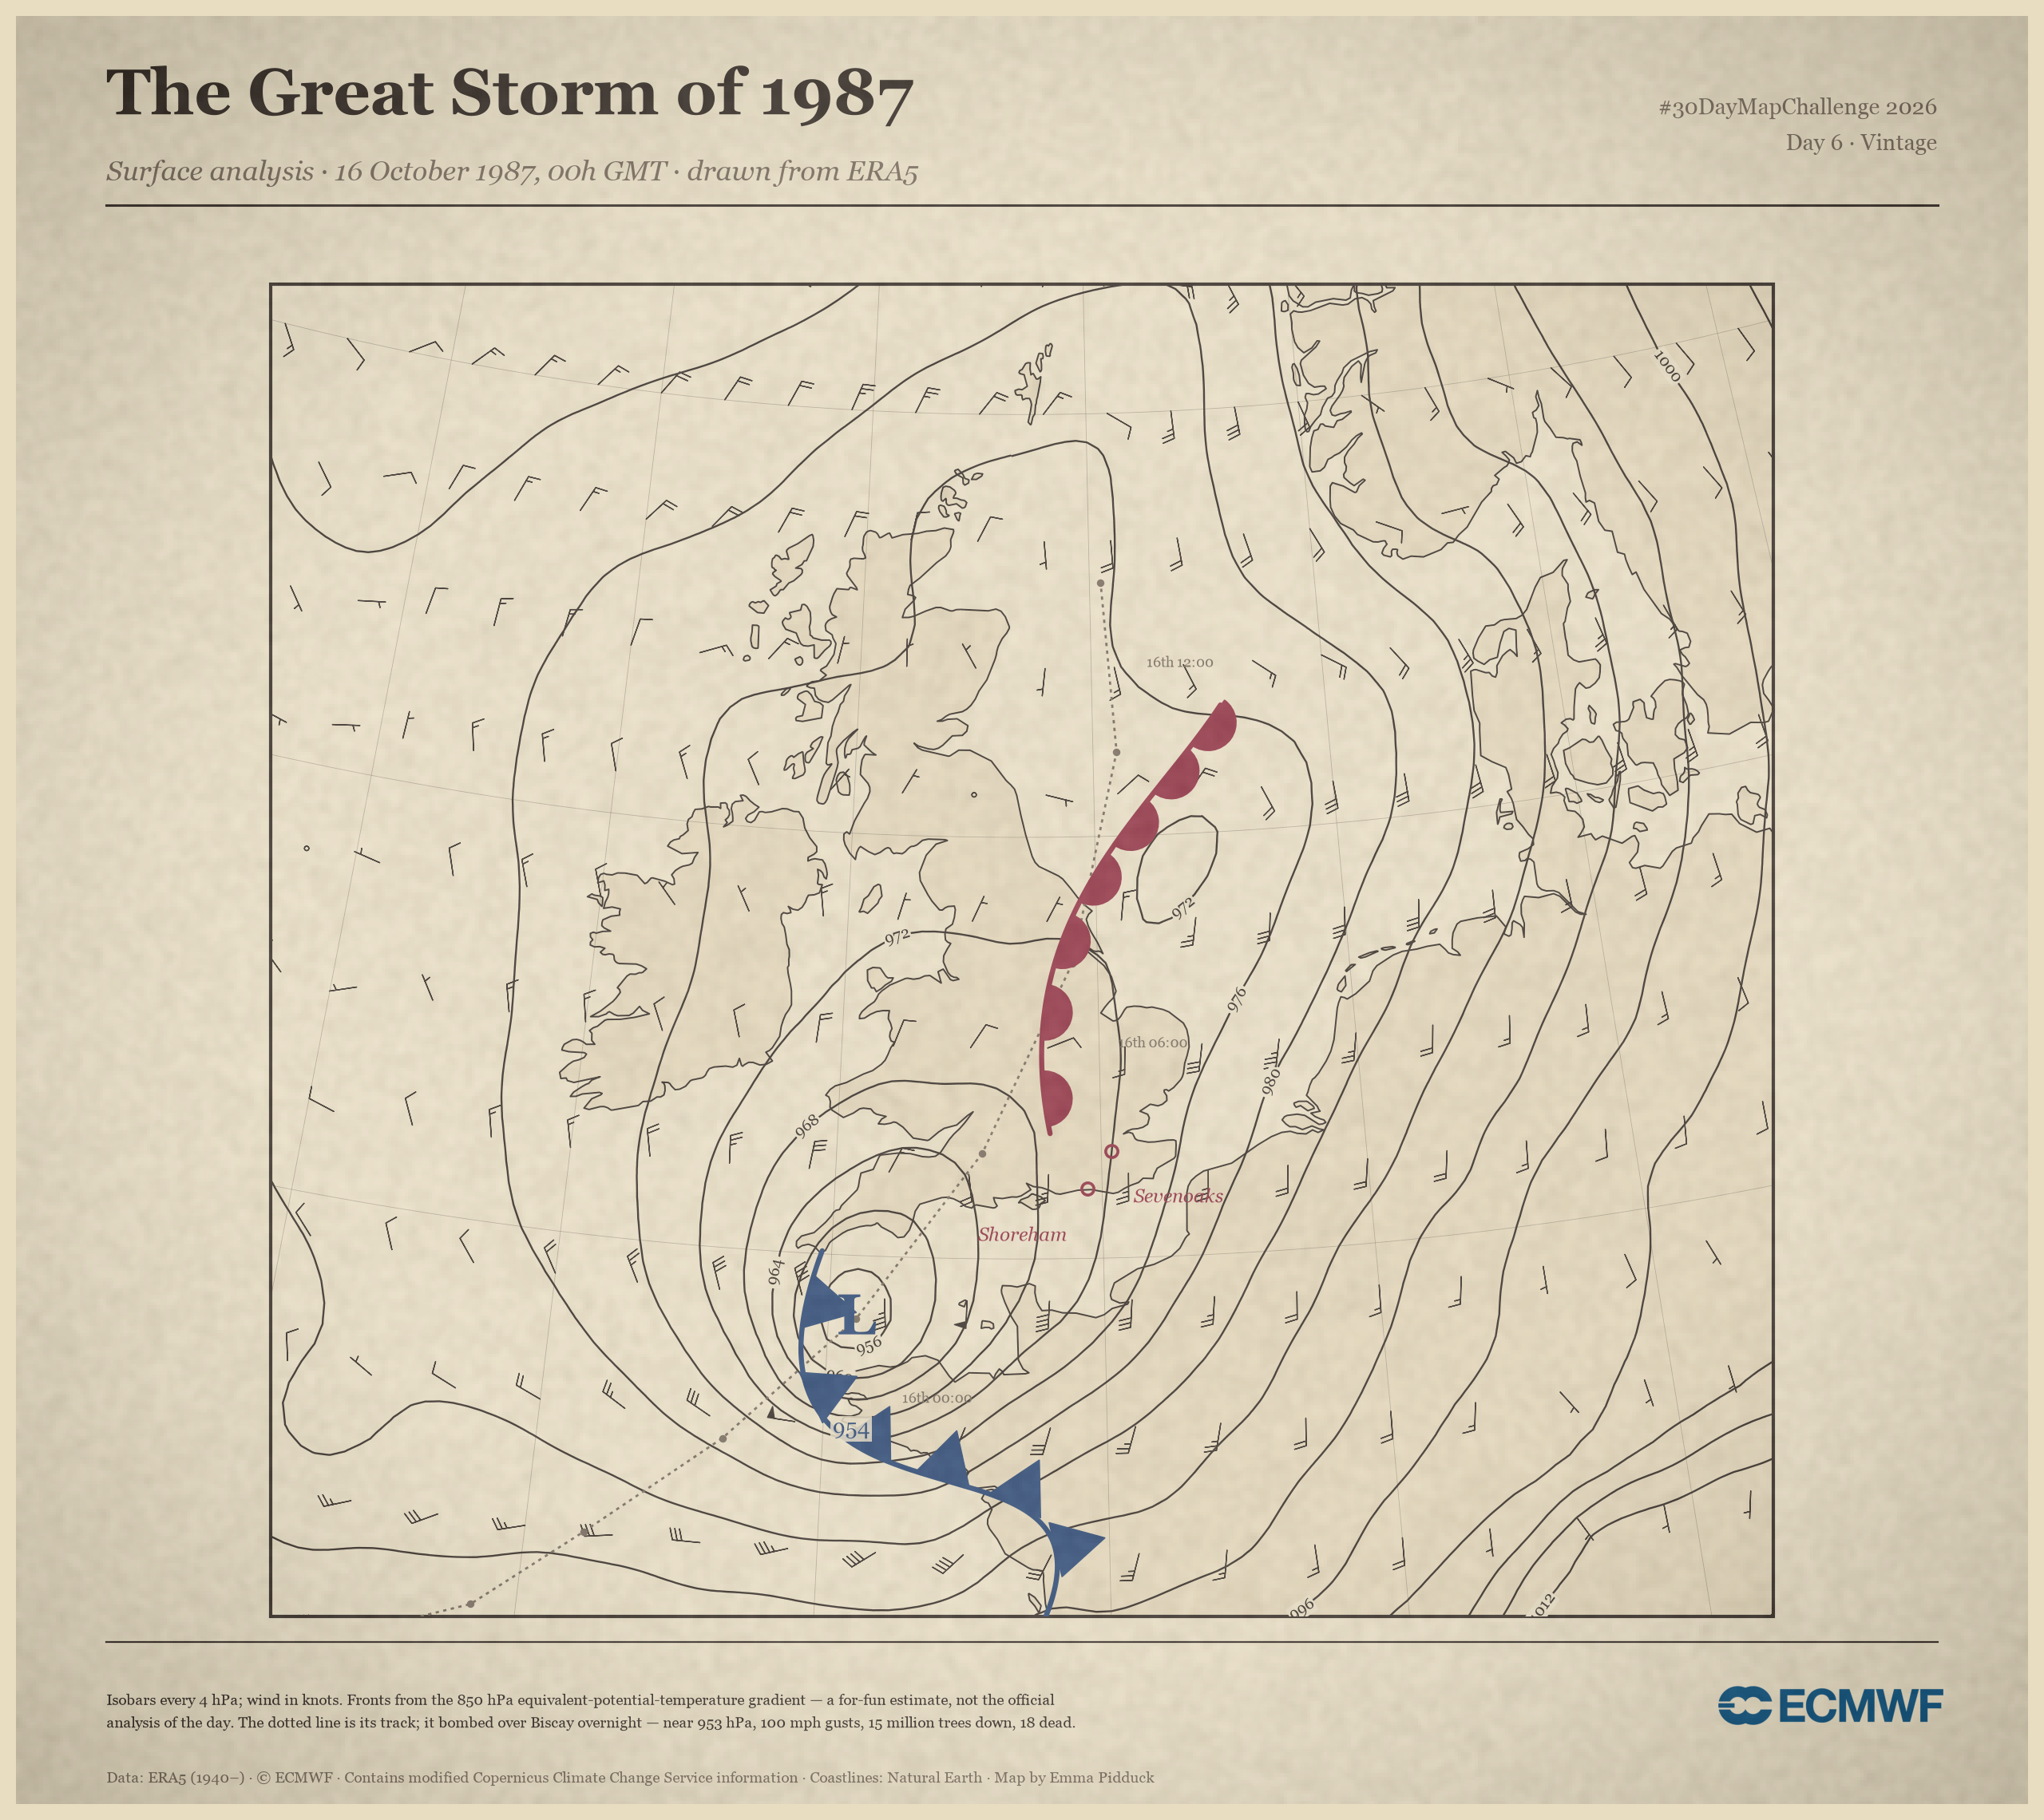

In [5]:
import matplotlib.pyplot as plt, matplotlib.image as mpimg
from matplotlib.patches import Polygon, Wedge
import cartopy.crs as ccrs, cartopy.feature as cfeature
from scipy.interpolate import splprep, splev

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Georgia", "Palatino", "DejaVu Serif"]
proj = ccrs.LambertConformal(central_longitude=-1.5, central_latitude=54, standard_parallels=(45, 62))
PC = ccrs.PlateCarree()

fig = plt.figure(figsize=(12.6, 11.2), dpi=200); fig.patch.set_facecolor(PAPER)
ax = fig.add_axes([0.045, 0.105, 0.91, 0.745], projection=proj)
ax.set_extent(EXTENT, PC); ax.set_facecolor(PAPER)
ax.spines["geo"].set_edgecolor(INK); ax.spines["geo"].set_linewidth(1.5)
ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="#e2d4b4", zorder=0)
ax.add_feature(cfeature.OCEAN.with_scale("50m"), facecolor=PAPER, zorder=0)
ax.add_feature(cfeature.COASTLINE.with_scale("50m"), edgecolor=INK, linewidth=0.7, zorder=3)
ax.gridlines(linewidth=0.3, color=FADE, alpha=0.45, xlocs=range(-30, 31, 5), ylocs=range(40, 71, 5), zorder=1)

cs = ax.contour(lon, lat, msl, levels=np.arange(920, 1081, 4), colors=INK, linewidths=0.85, transform=PC, zorder=4)
try: arts = cs.collections
except AttributeError: arts = [cs]
for a in arts: a.set_sketch_params(1.3, 190, 3)
for t in ax.clabel(cs, inline=True, fmt="%d", fontsize=7.2, colors=INK, inline_spacing=4):
    t.set_bbox(dict(fc=PAPER, ec="none", pad=0.5))

st = 6
ax.barbs(lon[::st], lat[::st], u[::st, ::st], v[::st, ::st], length=5.0, linewidth=0.5, color=INK,
         transform=PC, zorder=5, sizes=dict(emptybarb=0.08, spacing=0.17, height=0.42))

def theta_at(lo, la):
    i = int(np.clip(np.searchsorted(lon, lo), 0, len(lon) - 1))
    j = int(np.clip(np.argmin(np.abs(lat - la)), 0, len(lat) - 1))
    return theta_e[j, i]

def draw_front(pts, kind, col, n=9, smooth=3.0, h=70e3):
    tck, _ = splprep([pts[:, 0], pts[:, 1]], s=smooth, k=3)
    fl, fa = splev(np.linspace(0, 1, 260), tck)
    XY = proj.transform_points(PC, np.asarray(fl), np.asarray(fa))[:, :2]
    ax.plot(XY[:, 0], XY[:, 1], color=col, lw=2.3, zorder=7, solid_capstyle="round")
    for i in np.linspace(14, len(XY) - 15, n).astype(int):
        t = XY[i + 6] - XY[i - 6]; t /= np.hypot(*t); nrm = np.array([-t[1], t[0]])
        side = [theta_at(*PC.transform_point(*(XY[i] + s * nrm * 90e3), proj)) for s in (1, -1)]
        nn = nrm if side[0] >= side[1] else -nrm
        if kind == "cold":
            ax.add_patch(Polygon(np.array([XY[i]-t*h*0.52, XY[i]+t*h*0.52, XY[i]+nn*h*0.95]),
                                 closed=True, fc=col, ec=col, lw=0.5, zorder=8))
        else:
            ang = np.degrees(np.arctan2(nn[1], nn[0]))
            ax.add_patch(Wedge(XY[i], h*0.52, ang-90, ang+90, fc=col, ec=col, lw=0.5, zorder=8))

for pts, kind in BANDS:
    draw_front(pts, kind, COLDC if kind == "cold" else WARMC, n=9 if len(pts) > 8 else 7)

def centres(F, kind, size=18, prom=1.5, sep=6.0):
    flt = minimum_filter(F, size) if kind == "L" else maximum_filter(F, size)
    yy, xx = np.where(F == flt); order = np.argsort([F[j, i] for j, i in zip(yy, xx)])
    if kind == "H": order = order[::-1]
    out = []
    for j, i in zip(yy[order], xx[order]):
        lo, la = lon[i], lat[j]
        if not (EXTENT[0]+1.5 < lo < EXTENT[1]-1.5 and EXTENT[2]+1.5 < la < EXTENT[3]-1.5): continue
        w = F[max(0, j-18):j+19, max(0, i-18):i+19]
        if (w.max()-F[j, i] if kind == "L" else F[j, i]-w.min()) < prom: continue
        if any(np.hypot(lo-o[0], la-o[1]) < sep for o in out): continue
        out.append((lo, la, F[j, i]))
    return out

for kind, col in (("L", COLDC), ("H", INK)):
    cc = centres(msl, kind)
    if kind == "L": cc = cc[:1]                     # focus on the storm itself
    for lo, la, p in cc:
        ax.text(lo, la, kind, transform=PC, ha="center", va="center", fontsize=26, fontweight="bold", color=col, zorder=9)
        ax.text(lo, la-1.3, f"{p:.0f}", transform=PC, ha="center", va="center", fontsize=10, color=col, zorder=9,
                bbox=dict(fc=PAPER, ec="none", pad=0.9, alpha=0.85))

# depression track, 15 Oct 12h -> 16 Oct 12h, searched in the storm's neighbourhood
tr = []
for tt in sfA.valid_time.values:
    s = str(tt)[:16]
    if not (("1987-10-15" in s and s[11:13] >= "12") or ("1987-10-16" in s and s[11:13] <= "12")): continue
    m = gaussian_filter(sfA.msl.sel(valid_time=tt).values / 100, 1.2)
    jwin = (lat >= 45) & (lat <= 58); iwin = (lon >= -14) & (lon <= 6)
    sub = m[np.ix_(jwin, iwin)]; jj, ii = np.unravel_index(np.nanargmin(sub), sub.shape)
    tr.append((lon[iwin][ii], lat[jwin][jj], s[8:10], s[11:16]))
TX = proj.transform_points(PC, np.array([p[0] for p in tr]), np.array([p[1] for p in tr]))[:, :2]
ax.plot(TX[:, 0], TX[:, 1], ls=(0, (1.5, 2)), lw=1.0, color=FADE, zorder=6)
ax.plot(TX[:, 0], TX[:, 1], "o", ms=2.4, color=FADE, zorder=6, ls="none")
for k in (4, 6, 8):                                 # 16th 00h (chart hour), 06h, 12h
    if k >= len(tr): continue
    lo, la, dd, hh = tr[k]
    ax.text(*(proj.transform_point(lo, la, PC) + np.array([6e4, -9.5e4])),
            f"{int(dd)}th {hh}", ha="left", va="top", fontsize=6.6, color=FADE, zorder=6)

# places the storm is remembered by
for lo, la, lb, ha in [(0.19, 51.27, "Sevenoaks", "left"), (-0.27, 50.83, "Shoreham", "right")]:
    ax.plot(lo, la, marker="o", ms=5.5, mfc="none", mec=WARMC, mew=1.3, transform=PC, zorder=9)
    ax.text(lo + (0.4 if ha == "left" else -0.4), la - 0.45, lb, transform=PC, ha=ha, va="top",
            fontsize=8.5, color=WARMC, style="italic", zorder=9)

# header, caption, attribution
fig.text(0.045, 0.945, "The Great Storm of 1987", fontsize=29, color=INK, fontweight="bold")
fig.text(0.045, 0.908, "Surface analysis \u00b7 16 October 1987, 00h GMT \u00b7 drawn from ERA5",
         fontsize=12.5, color=FADE, style="italic")
fig.text(0.955, 0.945, "#30DayMapChallenge 2026", fontsize=10, color=FADE, ha="right")
fig.text(0.955, 0.925, "Day 6 \u00b7 Vintage", fontsize=10, color=FADE, ha="right")
for y, lw in ((0.894, 1.1), (0.0905, 0.8)):
    fig.lines.append(plt.Line2D([0.045, 0.955], [y, y], transform=fig.transFigure, color=INK, lw=lw))
fig.text(0.045, 0.064,
    "Isobars every 4 hPa; wind in knots. Fronts from the 850 hPa equivalent-potential-temperature gradient \u2014 a for-fun estimate, not the official\n"
    "analysis of the day. The dotted line is its track; it bombed over Biscay overnight \u2014 near 953 hPa, 100 mph gusts, 15 million trees down, 18 dead.",
    fontsize=7.0, color=INK, va="top", linespacing=1.5)
fig.text(0.045, 0.012, "Data: ERA5 (1940\u2013) \u00b7 \u00a9 ECMWF \u00b7 Contains modified Copernicus Climate "
         "Change Service information \u00b7 Coastlines: Natural Earth \u00b7 Map by " + AUTHOR,
         fontsize=7, color=FADE)
try:
    la_ = fig.add_axes([0.846, 0.030, 0.112, 0.050]); la_.imshow(mpimg.imread("assets/ECMWF_Core_Logo_RGB.png")); la_.axis("off")
except FileNotFoundError: pass

rng = np.random.default_rng(1987)
ta = fig.add_axes([0, 0, 1, 1], zorder=20); ta.axis("off"); ta.patch.set_alpha(0)
ta.imshow(gaussian_filter(rng.random((520, 600)), 1.1), cmap="Greys", alpha=0.075, extent=[0, 1, 0, 1], aspect="auto")
yy, xx = np.mgrid[0:520, 0:600]
ta.imshow(np.clip(np.hypot((xx-300)/300, (yy-260)/260) - 0.75, 0, None), cmap="Greys", alpha=0.16, extent=[0, 1, 0, 1], aspect="auto")
ta.set_xlim(0, 1); ta.set_ylim(0, 1)

fig.savefig(OUT, facecolor=PAPER); print("saved", OUT)
plt.show()

## Note

The **isobars, winds and track are genuine** — this is where ERA5 places the storm at 16 October
1987, 00 UTC. The **fronts, though, are an approximation**: an objective estimate from the 850 hPa
θₑ gradient, drawn *for fun* to complete the period look — not the official hand-analysis, and a
simplification of the storm's true (bent-back, Shapiro–Keyser) structure. Only the *look* is
borrowed from the charts of the day. It sits beside Matthias's companion plate, *The Night of the
Great Flood* (31 January 1953), drawn in the same hand.

*Part of a #30DayMapChallenge 2026 series built on ECMWF / Copernicus open data.
Day 2 is Lines (the jet); Day 5 Sight (synthetic satellite); Day 20 Hexagons.*
